<a href="https://colab.research.google.com/github/aureamc/A05-pca/blob/main/MyVersion_notebook_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aurea McIntosh

**Date:** 10/19/26

In [7]:
# Your Phase 1 solution to the problem goes here.


# **Q1**

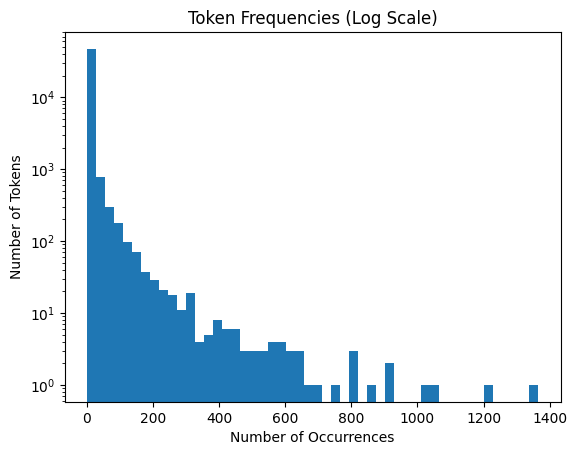

Top 15 most common words:
new : 1365
date : 1202
get : 1052
please : 1022
enron : 927
like : 923
2002 : 869
would : 806
one : 798
message : 795
call : 740
free : 691
software : 680
dear : 651
know : 644


In [8]:
import pickle
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd

# 1. Open and load the tokens file
file = open('all_tokens.pickle', 'rb')
all_tokens = pickle.load(file)
file.close()

# 2. Count how many times each word appears
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# 3. Pull out just the frequency numbers using a simple loop
frequencies = []
for token, count in token_freq:
    frequencies.append(count)

# 4. Plot a histogram of the word counts
plt.hist(frequencies, bins=50, log=True)
plt.title('Token Frequencies (Log Scale)')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens')
plt.show()

# 5. Print the top 15 most common words
print("Top 15 most common words:")
for token, count in token_freq[:15]:
    print(token, ":", count)

### **Q2**


In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Load the email dataset
df = pd.read_parquet('Phishing_clean.parquet')

# 2. Separate the target (Email Type) from the word columns
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# 3. Split the data into 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Create and train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Print how accurate the model is (R-squared score)
print("Training R2 Score:", model.score(X_train, y_train))
print("Test R2 Score:", model.score(X_test, y_test))

# 6. Find the words with the biggest influence
coefficients = pd.Series(model.coef_, index=X.columns)
largest_coeffs = coefficients.abs().sort_values(ascending=False)

print("\nTop words with the largest coefficients:")
for idx in largest_coeffs.head(10).index:
    print(idx, ":", coefficients[idx])

Training R2 Score: 0.7670143724934355
Test R2 Score: 0.6658718438847919

Top words with the largest coefficients:
intervention : -1.2592568996139137
localized : 0.8243504910175334
thermal : 0.7470064928454908
crawler : 0.6961666967309407
background-image: : -0.6229094422423072
helvetica, : 0.5985604340452578
aging : 0.5949564711693018
form. : 0.5768864773621444
gray; : -0.5744804020683508
a:active : 0.5744804020683503


# **Q3**

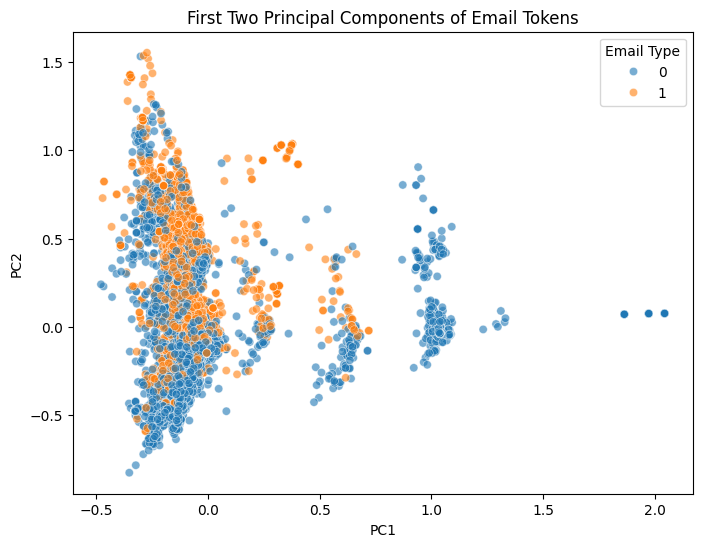

Explained variance by PC1: 0.01113090685988769
Explained variance by PC2: 0.008605731254648478


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import pandas as pd

# 1. Reduce all word columns down to just 2 principal components
pca_2 = PCA(n_components=2, random_state=42)
X_pca_2 = pca_2.fit_transform(X)

# 2. Put the 2 new components into a new table, along with the email type
pca_df = pd.DataFrame(X_pca_2, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values

# 3. Create a scatter plot to visualize safe vs. scam emails
plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Email Type', data=pca_df, alpha=0.6)
plt.title('First Two Principal Components of Email Tokens')
plt.show()

# Print variance explained
print("Explained variance by PC1:", pca_2.explained_variance_ratio_[0])
print("Explained variance by PC2:", pca_2.explained_variance_ratio_[1])

# **Q4**

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 1. Reduce the features down to 2,610 components using PCA
pca_2610 = PCA(n_components=2610, random_state=42)
X_pca_2610 = pca_2610.fit_transform(X)

# 2. Split the PCA-transformed data into training and testing sets
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca_2610, y, test_size=0.2, random_state=42
)

# 3. Train a linear regression model on the PCA features
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train_pca)

# 4. Print the new R-squared scores
print("PCA Training R2 Score:", model_pca.score(X_train_pca, y_train_pca))
print("PCA Test R2 Score:", model_pca.score(X_test_pca, y_test_pca))

# **Q5**

1. Preventing words from "battling" each other: In the case of text data,there are specific words that tend to be associated with one another. With the help of thousands of such overlapping words, standard regression cannot work properly and gives unstable results. PCA converts all these overlapping words into brand new independent variables.
2. Filtering out the random noise: With thousands of words, there will definitely be some words that occur only once or twice. These words may serve as a kind of "noise" that fools the model and causes it to remember the training data rather than learn patterns. PCA helps to get rid of this random noise by keeping only the most essential components.
That is why the performance of the model on the test sample increased.
3. Saving computing power: It consumes much computer memory to deal with such a big table.